### Probar diferentes parametros para el AG y visualizar los resultados

In [4]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

from pendulo_env_incisoB import ParametrosPlanta, PenduloEnv
from mpc_no_lineal import MPCNoLineal, costo_terminal_cuadratico, riccati
from Algoritmo_Genetico import RedEstimadora


In [5]:
# Parámetros nominales de referencia (usados por resumen_tiempos y graficar)
p = ParametrosPlanta()

# Cargar la red óptima entrenada (asegurate de que capas_ocultas y activacion coincidan con el entrenamiento)
red_optima = RedEstimadora(
    dim_entrada=12,
    capas_ocultas=(10, 10),
    dim_salida=4,
    activacion=nn.Tanh,
)
red_optima.load_state_dict(torch.load("mejor_red_estimadora.pt", map_location="cpu"))
red_optima.eval()
print(f"Red cargada correctamente ({red_optima.cantidad_pesos()} parámetros entrenables).")

Red cargada correctamente (284 parámetros entrenables).


In [6]:
def politica_mpc(mpc, theta_inicial=None):
    """Política MPC estándar (sin adaptación paramétrica)."""
    mpc.reiniciar(theta_inicial=theta_inicial)

    def _politica(estado):
        u_opt, _ = mpc.solve(estado)
        return np.array([u_opt])

    return _politica


def politica_mpc_adaptativa(
    mpc: MPCNoLineal,
    red: RedEstimadora,
    params_iniciales=(3.0, 1.0, 0.50, 0.01),
    escala_delta=(0.05, 0.02, 0.02, 0.002),
    historial_params: list | None = None,
):
    """Política MPC con actualización online de [M, m, L, r] mediante la red neuronal."""
    theta_mpc = np.asarray(params_iniciales, dtype=np.float64).reshape(4).copy()
    escala = np.asarray(escala_delta, dtype=np.float64)
    mpc.reiniciar(theta_inicial=theta_mpc)

    estado_interno = {"x_pred": None}

    def _politica(estado):
        nonlocal theta_mpc

        # A partir del paso 1, calcular el error de predicción y corregir parámetros
        if estado_interno["x_pred"] is not None:
            error_prediccion = estado - estado_interno["x_pred"]
            delta_theta = red.predecir(
                params_actuales=theta_mpc,
                estado_observado=estado,
                error_prediccion=error_prediccion,
            )
            theta_mpc = theta_mpc + escala * delta_theta

        if historial_params is not None:
            historial_params.append(theta_mpc.copy())

        u_opt, x_pred_siguiente = mpc.solve(estado, theta=theta_mpc)
        estado_interno["x_pred"] = x_pred_siguiente
        return np.array([u_opt])

    return _politica


def correr_episodio(env, politica, estado_inicial, renderizar=False, max_pasos=None):
    estado, _ = env.reset(options={"estado": estado_inicial})
    cuadros = [env.render()] if renderizar else []
    estados, fuerzas = [estado], []
    retorno, terminado = 0.0, False
    while not terminado:
        accion = politica(estado)
        estado, recompensa, terminated, truncated, info = env.step(accion)
        if renderizar:
            cuadros.append(env.render())
        estados.append(estado)
        fuerzas.append(info["fuerza"])
        retorno += recompensa
        terminado = terminated or truncated or (max_pasos is not None and len(fuerzas) >= max_pasos)
    print(f"{len(fuerzas)} pasos, retorno {retorno:.1f}, "
          f"fuera del riel {info['fuera_riel']}, caído {info['caido']}")
    return cuadros, np.array(estados), np.array(fuerzas)


def resumen_tiempos(mpc):
    t = 1e3 * np.array(mpc.tiempos_solve)
    print(f"solve: medio {t.mean():.1f} ms, p95 {np.percentile(t, 95):.1f} ms, "
          f"máx {t.max():.1f} ms, {np.mean(t > 1e3 * p.dt):.0%} arriba de {1e3 * p.dt:.0f} ms")
    return t


def animar(cuadros, estados, dt, cada=1):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.axis("off")
    imagen = ax.imshow(cuadros[0])
    titulo = ax.set_title("")

    def actualizar(i):
        imagen.set_data(cuadros[i])
        titulo.set_text(f"t = {i * dt:.2f} s   θ = {np.rad2deg(estados[i, 2]):.1f}°   x = {estados[i, 0]:.2f} m")
        return [imagen, titulo]

    indices = range(0, len(cuadros), cada)
    anim = animation.FuncAnimation(fig, actualizar, frames=indices, interval=1000 * dt * cada)
    plt.close(fig)
    return HTML(anim.to_jshtml())


def graficar(corridas, dt):
    """corridas es un dict {etiqueta: (estados, fuerzas)} para superponer."""
    fig, ejes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
    for etiqueta, (estados, fuerzas) in corridas.items():
        t = np.arange(len(estados)) * dt
        ejes[0].plot(t, np.rad2deg(estados[:, 2]), label=etiqueta)
        ejes[1].plot(t, estados[:, 0])
        ejes[2].step(t[:-1], fuerzas, where="post")
    ejes[0].set_ylabel("θ [°]")
    ejes[0].legend()
    for signo in (1, -1):
        ejes[1].axhline(signo * p.x_max, color="gray", ls="--")
    ejes[1].set_ylabel("x [m]")
    ejes[2].set_ylabel("F [N]")
    ejes[2].set_xlabel("t [s]")
    plt.tight_layout()
    plt.show()

In [7]:
def animar_parametros(historial_params, params_reales, dt, cada=1):
    """Anima la evolución de los parámetros estimados y el descenso del error relativo."""
    hist = np.asarray(historial_params, dtype=float)
    reales = np.asarray(params_reales, dtype=float).reshape(4)
    n_pasos = len(hist)
    t = np.arange(n_pasos) * dt

    # Error relativo porcentual por parámetro y promedio global
    err_rel_pct = 100.0 * np.abs(hist - reales) / np.maximum(np.abs(reales), 1e-8)
    err_global_pct = np.mean(err_rel_pct, axis=1)

    fig = plt.figure(figsize=(10, 6.5))
    gs = fig.add_gridspec(3, 2, height_ratios=[1.15, 1.0, 1.0], hspace=0.45, wspace=0.28)

    ax_err = fig.add_subplot(gs[0, :])
    axs_p = [
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
        fig.add_subplot(gs[2, 0]),
        fig.add_subplot(gs[2, 1]),
    ]

    # Configurar gráfico superior: descenso del error porcentual medio
    ax_err.set_xlim(0, t[-1])
    ax_err.set_ylim(0, max(5.0, np.max(err_global_pct) * 1.15))
    ax_err.set_ylabel("Error medio [%]")
    ax_err.set_xlabel("t [s]")
    ax_err.grid(True, alpha=0.3)
    linea_err, = ax_err.plot([], [], color="crimson", lw=2, label="Error relativo medio")
    punto_err, = ax_err.plot([], [], "o", color="crimson")
    ax_err.legend(loc="upper right")
    titulo = ax_err.set_title("")

    # Configurar los 4 subgráficos de parámetros físicos
    nombres = ["M (Carro) [kg]", "m (Péndulo) [kg]", "L (Largo) [m]", "r (Radio) [m]"]
    lineas_est, puntos_est = [], []

    for idx, ax in enumerate(axs_p):
        y_min = min(np.min(hist[:, idx]), reales[idx])
        y_max = max(np.max(hist[:, idx]), reales[idx])
        margen = max(0.15 * (y_max - y_min), 0.1 * abs(reales[idx]), 1e-3)

        ax.set_xlim(0, t[-1])
        ax.set_ylim(y_min - margen, y_max + margen)
        ax.axhline(reales[idx], color="black", ls="--", lw=1.3, label=f"Real ({reales[idx]:.3f})")
        ax.set_ylabel(nombres[idx])
        if idx >= 2:
            ax.set_xlabel("t [s]")
        ax.grid(True, alpha=0.3)

        l_est, = ax.plot([], [], color="tab:blue", lw=2, label="Estimado NN")
        p_est, = ax.plot([], [], "o", color="tab:blue", markersize=5)
        ax.legend(loc="best", fontsize=8)
        lineas_est.append(l_est)
        puntos_est.append(p_est)

    def actualizar(i):
        t_actual = t[: i + 1]
        linea_err.set_data(t_actual, err_global_pct[: i + 1])
        punto_err.set_data([t[i]], [err_global_pct[i]])
        titulo.set_text(
            f"t = {t[i]:.2f} s  |  Error Paramétrico Medio: {err_global_pct[i]:.2f}% "
            f"(Inicial: {err_global_pct[0]:.2f}%)"
        )

        for idx in range(4):
            lineas_est[idx].set_data(t_actual, hist[: i + 1, idx])
            puntos_est[idx].set_data([t[i]], [hist[i, idx]])

        return [linea_err, punto_err, titulo, *lineas_est, *puntos_est]

    indices = range(0, n_pasos, cada)
    anim = animation.FuncAnimation(fig, actualizar, frames=indices, interval=1000 * dt * cada)
    plt.close(fig)
    return HTML(anim.to_jshtml())

--- MPC Nominal (sin red) ---
200 pasos, retorno -990.9, fuera del riel False, caído False

--- MPC Adaptativo (con Red Estimadora) ---
176 pasos, retorno -2187.2, fuera del riel False, caído True
solve: medio 27.8 ms, p95 34.0 ms, máx 72.5 ms, 99% arriba de 20 ms


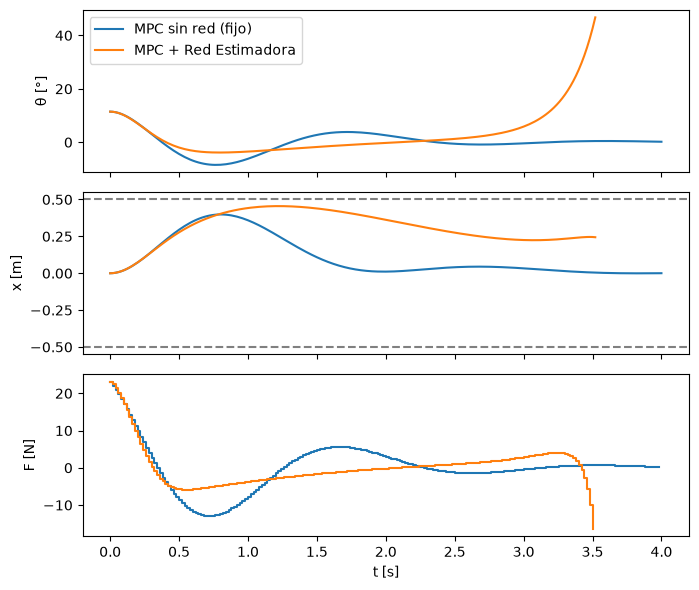

In [8]:
# Configuración del experimento: planta real distinta a los parámetros nominales del MPC
params_reales = (4.5, 1.4, 0.70, 0.02)
params_nominales = (3.0, 1.0, 0.50, 0.01)
escala_delta = (0.05, 0.02, 0.02, 0.002)
estado_inicial = np.array([0.0, 0.0, 0.20, 0.0])
max_pasos = 200

# 1. Crear entorno de planta real con render_mode="rgb_array" para capturar cuadros
env_real = PenduloEnv(
    parametros=ParametrosPlanta(),
    render_mode="rgb_array",
    M=params_reales[0],
    m=params_reales[1],
    L=params_reales[2],
    r=params_reales[3],
)

# 2. Instanciar controlador MPC no lineal con costo terminal LQR
p_mpc = ParametrosPlanta()
P_riccati, _ = riccati(p_mpc)
mpc = MPCNoLineal(p=p_mpc, N=20, costo_terminal=costo_terminal_cuadratico(P_riccati))

# Corrida A: MPC sin adaptación (parámetros fijos equivocados)
print("--- MPC Nominal (sin red) ---")
_, estados_fijo, fuerzas_fijo = correr_episodio(
    env_real,
    politica_mpc(mpc, theta_inicial=params_nominales),
    estado_inicial=estado_inicial,
    renderizar=False,
    max_pasos=max_pasos,
)

# Corrida B: MPC con adaptación online mediante la red entrenada
print("\n--- MPC Adaptativo (con Red Estimadora) ---")
historial_params = []
cuadros_adapt, estados_adapt, fuerzas_adapt = correr_episodio(
    env_real,
    politica_mpc_adaptativa(
        mpc,
        red_optima,
        params_iniciales=params_nominales,
        escala_delta=escala_delta,
        historial_params=historial_params,
    ),
    estado_inicial=estado_inicial,
    renderizar=True,
    max_pasos=max_pasos,
)
resumen_tiempos(mpc)
env_real.close()

# Comparación estática de trayectorias
graficar(
    {
        "MPC sin red (fijo)": (estados_fijo, fuerzas_fijo),
        "MPC + Red Estimadora": (estados_adapt, fuerzas_adapt),
    },
    dt=p.dt,
)

# Animación 1: Respuesta física del carrito y péndulo
animar(cuadros_adapt, estados_adapt, dt=p.dt, cada=2)

In [ ]:
# Animación 2: Convergencia de [M, m, L, r] y caída del error porcentual
animar_parametros(historial_params, params_reales=params_reales, dt=p.dt, cada=2)

In [ ]:
escenarios = [
    {
        "nombre": "1. Carro pesado + péndulo largo",
        "reales": (5.2, 1.6, 0.80, 0.025),
        "x0": [0.0, 0.0, 0.18, 0.0],
        "b_carro": 0.0,
    },
    {
        "nombre": "2. Carro liviano + péndulo corto",
        "reales": (2.0, 0.6, 0.35, 0.008),
        "x0": [0.0, 0.0, -0.22, 0.0],
        "b_carro": 0.0,
    },
    {
        "nombre": "3. Ángulo inicial exigente (16°)",
        "reales": (4.0, 1.3, 0.65, 0.015),
        "x0": [-0.15, 0.2, np.deg2rad(16.0), -0.3],
        "b_carro": 0.0,
    },
    {
        "nombre": "4. Con fricción no modelada en riel",
        "reales": (4.5, 1.4, 0.70, 0.02),
        "x0": [0.0, 0.0, 0.18, 0.0],
        "b_carro": 1.5,
    },
]

resultados_grafica = {}

for esc in escenarios:
    print(f"\n=== {esc['nombre']} | Reales: {esc['reales']} ===")
    p_test = ParametrosPlanta()
    p_test.b_carro = esc["b_carro"]

    env_test = PenduloEnv(
        parametros=p_test,
        M=esc["reales"][0],
        m=esc["reales"][1],
        L=esc["reales"][2],
        r=esc["reales"][3],
    )

    hist_p = []
    _, est_test, fuer_test = correr_episodio(
        env_test,
        politica_mpc_adaptativa(
            mpc,
            red_optima,
            params_iniciales=params_nominales,
            escala_delta=escala_delta,
            historial_params=hist_p,
        ),
        estado_inicial=np.array(esc["x0"], dtype=float),
        renderizar=False,
        max_pasos=200,
    )
    env_test.close()

    reales_arr = np.array(esc["reales"])
    err_ini = np.mean(100.0 * np.abs(np.array(params_nominales) - reales_arr) / reales_arr)
    err_fin = np.mean(100.0 * np.abs(hist_p[-1] - reales_arr) / reales_arr)
    print(f"Parámetros finales estimados: {np.round(hist_p[-1], 4)}")
    print(f"Error medio: {err_ini:.1f}% -> {err_fin:.1f}%")

    resultados_grafica[esc["nombre"]] = (est_test, fuer_test)

graficar(resultados_grafica, dt=p.dt)